# DGCA domestic airlines: dashboard and report pieces
Third notebook, to run after the download and cleaning notebooks. It reads `data/raw`, `data/interim` and `data/clean`, and writes figures to `outputs/figures/` and two small tables to `data/clean/`.

| Rubric item | Cell |
|---|---|
| Data dictionary with checked units (storage) | 2 |
| Each outlier diagnosed as error or real value (cleaning) | 3 |
| Plot comparing the data before and after cleaning (visualisation) | 4 |
| Dashboard of six plots, each with a caption containing numbers (visualisation) | 5 to 7 |
| Attributions and contributions (presentation) | last cell |

## 1. Setup

In [1]:
# SETUP: paths, data, style
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

TODAY = pd.Timestamp.today().date().isoformat()
_here = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in [_here, *_here.parents] if (p / "data" / "clean").is_dir())
RAW, INTERIM, CLEAN = (PROJECT_ROOT / "data" / d for d in ("raw", "interim", "clean"))
FIG = PROJECT_ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
latest = lambda folder, pat: sorted(folder.glob(pat))[-1]

clean = pd.read_parquet(latest(CLEAN, "dgca_domestic_clean_*.parquet"))
interim = pd.read_csv(latest(INTERIM, "dgca_domestic_airline_monthly_*.csv"))      # the table before cleaning
rec = pd.read_csv(latest(CLEAN, "total_domestic_reconciliation_*.csv"), parse_dates=["Date"])
gh = pd.read_csv(latest(RAW / "github", "vonter_domestic_carrier_*.csv"))
LAST_COMPLETE = rec.loc[rec.within_2pct, "Date"].max()          # last month where airlines add up to DGCA's total

HIGHLIGHT, DARK, MID, LIGHT = "#d95f02", "#404040", "#8c8c8c", "#cfcfcf"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
print("root:", PROJECT_ROOT, "| clean rows:", len(clean), "| analysis ends:", LAST_COMPLETE.strftime("%Y-%m"))

root: /home/god/Downloads/DGCA_aviation_analysis | clean rows: 1957 | analysis ends: 2026-08


## 2. Data dictionary with units checked against the raw header rows
The header rows of all raw workbooks are scanned first, so the units in the dictionary are evidence, not guesses.

In [2]:
# DATA DICTIONARY with units checked against the raw header rows (replaces the 'unverified' units)
import glob, re
from collections import Counter

# evidence: the unit phrases in the header rows are identical in every raw workbook
sig = Counter()
for p in sorted(glob.glob(str(RAW / "dgca_xlsx" / "*.xlsx"))):
    h = pd.read_excel(p, header=None, sheet_name=0, nrows=4).iloc[1:3].values.ravel()
    sig[tuple(re.findall(r"\(IN [A-Z]+\)", " ".join(str(x) for x in h if pd.notna(x)).upper()))] += 1
print(f"{sum(sig.values())} workbooks checked; distinct header-unit patterns found: {len(sig)}  (1 means every file uses the same units)")

META = {   # column: (unit, meaning, allowed range). Meanings quote the DGCA header text.
    "Type": ("-", "Section of the DGCA workbook", "ScheduledDomestic | NonScheduledDomestic"),
    "Group": ("-", "Airline brand mapped to today's group (our grouping, see cleaning log)", "20 values"),
    "Airline": ("-", "Airline brand as named in the DGCA file", "-"),
    "Date": ("month start", "First day of the reporting month (from file year + month row)", "2017-01-01 to latest published month"),
    "Year": ("year", "Reporting year", "2017-2026"),
    "Month": ("month number", "Reporting month", "1-12"),
    "Source File": ("-", "DGCA workbook the row came from", "-"),
    "Source Sheet": ("-", "Sheet the row was read from", "-"),
    "Aircraft Number": ("departures (count)", "Header: AIRCRAFT FLOWN / DEPARTURES (IN NUMBER)", ">= 0"),
    "Aircraft Hours": ("hours", "Header: AIRCRAFT FLOWN / HOURS (IN NUMBER)", ">= 0"),
    "Aircraft Kilometres": ("thousand km", "Header: AIRCRAFT FLOWN / KILOMETRE (IN THOUSAND)", ">= 0"),
    "Passenger Number": ("passengers (count)", "Header: PASSENGERS CARRIED (IN NUMBER)", ">= 0"),
    "Passenger Kilometers": ("thousand passenger-km", "Header: PASSENGER KMS. PERFORMED (IN THOUSAND)", ">= 0 and <= Seat Kilometers"),
    "Seat Kilometers": ("thousand seat-km", "Header: AVAILABLE SEAT KILOMETRE (IN THOUSAND)", ">= 0"),
    "Passenger Load Factor": ("percent", "DGCA note: (PAX KM PERFORMED / AVAILABLE SEAT KMS) x 100", "0-100; empty when seat km = 0"),
}
rows = []
for c in clean.columns:
    unit, meaning, rng = META[c]
    obs = ""
    if pd.api.types.is_numeric_dtype(clean[c]) and c not in ("Year", "Month"):
        obs = f"{clean[c].min():,.1f} to {clean[c].max():,.1f}"
    elif c == "Date":
        obs = f"{clean[c].min():%Y-%m} to {clean[c].max():%Y-%m}"
    rows.append((c, str(clean[c].dtype), unit, "DGCA monthly traffic statistics" if c in list(META)[8:] else "derived", meaning, rng, obs))
dictionary = pd.DataFrame(rows, columns=["column", "dtype", "unit", "source", "meaning", "allowed_range", "observed_range"])
dictionary.to_csv(CLEAN / f"data_dictionary_{TODAY}.csv", index=False)
dictionary

142 workbooks checked; distinct header-unit patterns found: 1  (1 means every file uses the same units)


,column,dtype,unit,source,meaning,allowed_range,observed_range
0,Type,str,-,derived,Section of the DGCA workbook,ScheduledDomestic | NonScheduledDomestic,
1,Group,str,-,derived,Airline brand mapped to today's group (our gro...,20 values,
2,Airline,string,-,derived,Airline brand as named in the DGCA file,-,
3,Date,datetime64[ns],month start,derived,First day of the reporting month (from file ye...,2017-01-01 to latest published month,2017-01 to 2026-09
4,Year,int64,year,derived,Reporting year,2017-2026,
5,Month,int64,month number,derived,Reporting month,1-12,
6,Source File,str,-,derived,DGCA workbook the row came from,-,
7,Source Sheet,str,-,derived,Sheet the row was read from,-,
8,Aircraft Number,Float64,departures (count),DGCA monthly traffic statistics,Header: AIRCRAFT FLOWN / DEPARTURES (IN NUMBER),>= 0,"0.0 to 62,993.0"
9,Aircraft Hours,Float64,hours,DGCA monthly traffic statistics,Header: AIRCRAFT FLOWN / HOURS (IN NUMBER),>= 0,"0.0 to 113,100.6"


## 3. Outlier diagnosis
The 53 flagged rows are tested two ways, then given a likely cause.
1. **Is the row internally consistent?** Average trip length (passenger-km / passengers) must be plausible and the load factor must equal passenger-km / seat-km x 100. These tests would catch a unit slip or a typing error in DGCA's own table.
2. **Does a second parse of the same DGCA file agree?** Vonter's CSV must show the same passenger number. This tests our parser, not DGCA's reporting.

A row that passes both is kept as reported. The likely cause comes from the airline's own history (COVID window, last month of operation, launch month, tiny carrier). Rows marked "cause still to confirm" need a news check before the report claims a cause.

In [3]:
# OUTLIER DIAGNOSIS: for every flagged row, test whether it is a recording error, then name the likely cause
out = pd.read_csv(latest(CLEAN, "outlier_review_*.csv"), parse_dates=["Date"])
sd = clean[clean.Type == "ScheduledDomestic"]
d = out.merge(sd[["Airline", "Date", "Passenger Kilometers", "Seat Kilometers", "Year", "Month"]], on=["Airline", "Date"], how="left")

# test 1: internal consistency within DGCA's own row. Average trip length must be plausible (50 km allows helicopter hops), and load factor must equal PKP/SKP*100
d["avg_trip_km"] = d["Passenger Kilometers"] * 1000 / d["Passenger Number"].where(d["Passenger Number"] > 0)
d["trip_ok"] = d.avg_trip_km.between(50, 3500) | d.avg_trip_km.isna()
lf_calc = d["Passenger Kilometers"] / d["Seat Kilometers"].where(d["Seat Kilometers"] > 0) * 100
d["lf_ok"] = ((lf_calc - d["Passenger Load Factor"]).abs() < 0.1) | lf_calc.isna()

# test 2: Vonter's separate parse of the same DGCA files must show the same number (this checks OUR parser, not DGCA's reporting)
g2 = gh[gh.Type == "ScheduledDomestic"][["Airline", "Year", "Month", "Passenger Number"]].rename(columns={"Passenger Number": "gh_pax"})
d = d.merge(g2, on=["Airline", "Year", "Month"], how="left")
# three outcomes: a missing GitHub record is NOT a pass, because nothing was compared
d["github_check"] = np.where(d.gh_pax.isna(), "no GitHub record", np.where((d.gh_pax - d["Passenger Number"]).abs() < 1, "match", "differs"))
d["github_ok"] = d.github_check.ne("differs")          # only an actual disagreement counts against the row

# likely cause, from the airline's own history
def cause(r):
    s = sd[sd.Airline == r.Airline].set_index("Date")["Passenger Number"].fillna(0)
    later, earlier = s[s.index > r.Date], s[s.index < r.Date]
    if r.Date >= clean.Date.max():
        return "newest month in the data: may still be provisional"
    if r.covid_window:
        return "COVID-19 restrictions (Mar-Jun 2020 / Apr-Jun 2021 windows)"
    if (later > 0).sum() == 0:
        return "no later traffic in the data: airline stopped, merged or stopped reporting (check which)"
    if (earlier > 0).sum() == 0:
        return "launch month: first traffic, partial month"
    if r["Passenger Number"] == 0:
        return "temporary suspension: zero month between operating months"
    if s[s > 0].median() < 25000:
        return "small carrier: a few hundred passengers move the percentage a lot"
    return "no rule matched: check news and the neighbouring months"
d["likely_cause"] = d.apply(cause, axis=1)

# named events: confirm each one against a news source and cite it in the report
EVENT_NOTES = {("Jet Airways", "2019-05"): "Jet Airways suspended operations in April 2019",
               ("Go First", "2023-05"): "Go First stopped flying in early May 2023 (insolvency filing)",
               ("Vistara", "2024-11"): "Vistara merged into Air India in November 2024",
               ("Akasa Air", "2022-08"): "Akasa Air began flying in August 2022"}
d["event_note"] = [EVENT_NOTES.get((a, t.strftime("%Y-%m")), "") for a, t in zip(d.Airline, d.Date)]

error_free = d.trip_ok & d.lf_ok & d.github_ok
d["diagnosis"] = np.where(~error_free, "possible recording error: investigate",
                  np.where(d.likely_cause.str.startswith("no rule"), "real value, cause still to confirm", "real value"))
# how far each row has really been checked. Nothing is "verified" until a source outside DGCA's own table (news, airline statement) is cited.
d["review_status"] = np.select(
    [~error_free, d.event_note.ne(""), d.likely_cause.str.startswith("no rule")],
    ["possible recording error: investigate", "plausible: named event, cite a source", "unresolved"],
    default="plausible: pattern fits the cause (rule-based, not verified)")
print(d.github_check.value_counts().to_string()); print()
print("flagged:", len(d), "| fail an internal/parser test:", int((~error_free).sum()))
d["action"] = np.where(d.diagnosis.str.startswith("possible"), "investigate", "keep as reported")

cols = ["Airline", "Date", "Passenger Number", "dev_vs_median", "avg_trip_km", "trip_ok", "lf_ok", "github_check",
        "likely_cause", "event_note", "diagnosis", "review_status", "action"]
d[cols].round({"dev_vs_median": 2, "avg_trip_km": 0}).to_csv(CLEAN / f"outlier_diagnosis_{TODAY}.csv", index=False)
print(d.diagnosis.value_counts().to_string()); print(); print(d.review_status.value_counts().to_string()); print()
print(d.likely_cause.value_counts().to_string())
d[d.diagnosis != "real value"][cols].round({"dev_vs_median": 2, "avg_trip_km": 0})

flagged: 53 | fail an internal/parser test: 0
diagnosis
real value                            49
real value, cause still to confirm     4

likely_cause
COVID-19 restrictions (Mar-Jun 2020 / Apr-Jun 2021 windows)          20
small carrier: a few hundred passengers move the percentage a lot    13
last month(s) of operation: airline stopped or merged                 9
launch month: first traffic, partial month                            5
no rule matched: check news and the neighbouring months               4
newest month in the data: may still be provisional                    1
temporary suspension: zero month between operating months             1


,Airline,Date,Passenger Number,dev_vs_median,avg_trip_km,trip_ok,lf_ok,github_ok,likely_cause,event_note,diagnosis,action
10,AirAsia India,2022-01-01,295094.0,-0.53,1063.0,True,True,True,no rule matched: check news and the neighbouri...,,"real value, cause still to confirm",keep as reported
33,Go First,2020-07-01,79358.0,-0.40,1043.0,True,True,True,no rule matched: check news and the neighbouri...,,"real value, cause still to confirm",keep as reported
51,TruJet,2021-08-01,26823.0,0.84,390.0,True,True,True,no rule matched: check news and the neighbouri...,,"real value, cause still to confirm",keep as reported
52,SpiceJet,2021-12-01,1150688.0,0.40,999.0,True,True,True,no rule matched: check news and the neighbouri...,,"real value, cause still to confirm",keep as reported


## 4. Before vs after cleaning

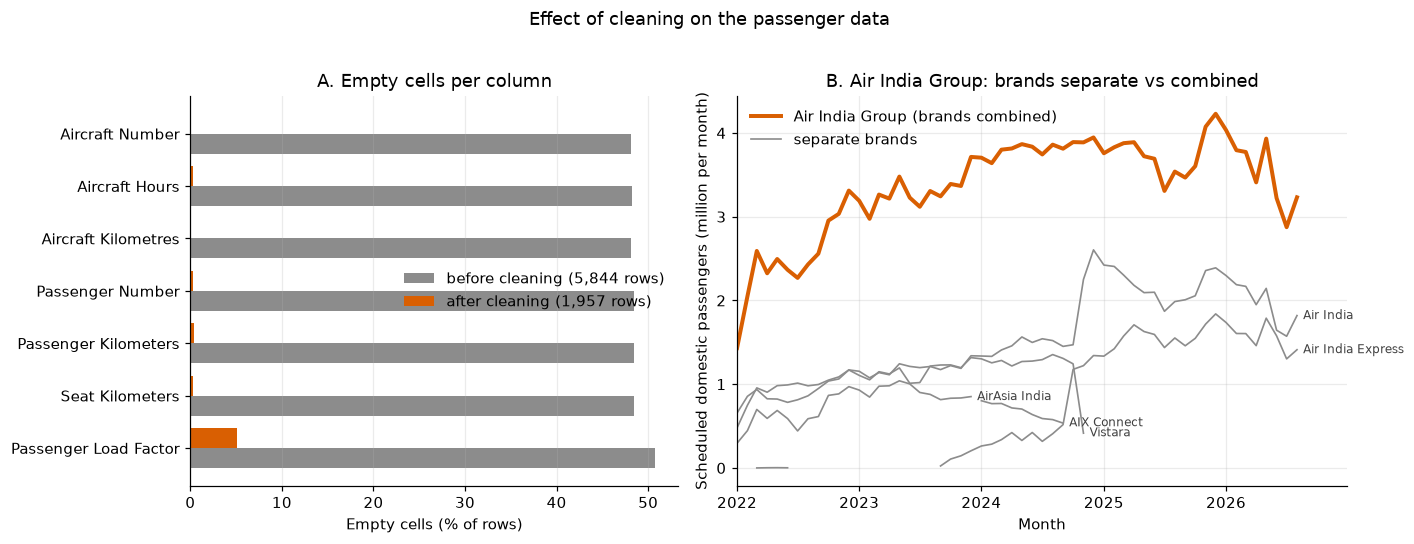

**Caption.** Panel A: removing the empty template rows cuts the empty share of Passenger Number from 48.4% to 0.3%, and of Passenger Load Factor from 50.8% to 5.1%, where 94 of the 100 remaining gaps are months with zero flying (0/0 is undefined, not missing). Panel B: Vistara reports 1.24 million passengers in Oct 2024 and nothing after its merger, so the Air India brand alone shows 1.47 to 2.60 million, while the combined group stays continuous (3.89 to 3.95 million).

In [4]:
# BEFORE vs AFTER CLEANING (rubric: at least one plot compares the data before and after cleaning)
core = ["Aircraft Number", "Aircraft Hours", "Aircraft Kilometres", "Passenger Number",
        "Passenger Kilometers", "Seat Kilometers", "Passenger Load Factor"]
# stage by stage, so a change of population (dropping sections and aggregate rows) is not mistaken for better data
M16 = ["Aircraft Number", "Aircraft Hours", "Aircraft Kilometres", "Passenger Number", "Passenger Kilometers", "Seat Kilometers", "Passenger Load Factor", "Freight", "Mail",
       "Total Cargo", "Passenger Tonne Kilometer", "Mail Tonne Kilometer", "Freight Tonne Kilometer", "Total Tonne Kilometer", "Available Tonne Kilometer", "Weight Load Factor"]
s0 = interim
s1 = s0[~s0[M16].isna().all(axis=1)]
s2 = s1[s1.Type == "ScheduledDomestic"]
s3 = s2[~s2.Airline.astype(str).str.casefold().str.replace(r"[_-]+", " ", regex=True).str.strip().eq("total domestic")]
stages = [("1. all parsed rows", s0), ("2. empty templates removed", s1), ("3. scheduled domestic only", s2), ("4. aggregate rows removed (final)", s3)]
na_stage = [(n, len(d_), d_[core].isna().mean() * 100) for n, d_ in stages]
na_before, na_after = na_stage[0][2], na_stage[1][2]          # same rows with and without the empty templates

sdf = clean[clean.Type == "ScheduledDomestic"]
brands = ["Air India", "Air India Express", "Vistara", "AirAsia India", "AIX Connect"]
brand_pax = sdf[sdf.Airline.isin(brands)].groupby(["Airline", "Date"])["Passenger Number"].sum().unstack("Airline") / 1e6
group_pax = sdf[sdf.Group == "Air India Group"].groupby("Date")["Passenger Number"].sum() / 1e6
x0, x1 = pd.Timestamp("2022-01-01"), LAST_COMPLETE

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
y = np.arange(len(core)); h = 0.2
for k, ((n, rows_, na_), col) in enumerate(zip(na_stage, ["#d9d9d9", MID, "#fdae6b", HIGHLIGHT])):
    a1.barh(y + (1.5 - k) * h, na_.values, h, color=col, label=f"{n} ({rows_:,} rows)")
a1.set_yticks(y); a1.set_yticklabels(core); a1.invert_yaxis(); a1.grid(axis="y", alpha=0)
a1.set_xlabel("Empty cells (% of rows)"); a1.set_title("A. Empty cells per column, at each step")
a1.legend(loc="lower right", frameon=False, fontsize=7.5)
for c in brand_pax.columns:
    s = brand_pax[c].loc[x0:x1]; a2.plot(s.index, s, color=MID, lw=1.1)
    last = s.dropna()
    if len(last): a2.annotate(c, (last.index[-1], last.iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8, color=DARK, va="center")
a2.plot(group_pax.loc[x0:x1].index, group_pax.loc[x0:x1], color=HIGHLIGHT, lw=2.6, label="Air India Group (brands combined)")
a2.plot([], [], color=MID, lw=1.1, label="separate brands")
a2.set_title("B. Air India Group: brands separate vs combined"); a2.set_xlabel("Month"); a2.set_ylabel("Scheduled domestic passengers (million per month)")
a2.legend(loc="upper left", frameon=False); a2.set_xlim(x0, x1 + pd.Timedelta(days=150))
import matplotlib.dates as mdates
a2.xaxis.set_major_locator(mdates.YearLocator()); a2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Effect of cleaning on the passenger data", y=1.02, fontsize=12)
plt.tight_layout(); fig.savefig(FIG / f"before_after_cleaning_{TODAY}.png", dpi=200, bbox_inches="tight"); plt.show()

o24, d24 = pd.Timestamp("2024-10-01"), pd.Timestamp("2024-12-01")
zero_rows = int((clean["Passenger Number"].eq(0) & clean["Passenger Kilometers"].eq(0) & clean["Seat Kilometers"].eq(0) & clean["Passenger Load Factor"].isna()).sum())
display(Markdown(
    f"**Caption.** Panel A: removing the empty template rows (same rows, steps 1 and 2) cuts the empty share of Passenger Number from {na_before['Passenger Number']:.1f}% to {na_after['Passenger Number']:.1f}%, "
    f"and of Passenger Load Factor from {na_before['Passenger Load Factor']:.1f}% to {na_after['Passenger Load Factor']:.1f}%. Steps 3 and 4 only change which rows are counted, so they are not a repair. Of the final table's gaps in load factor, {zero_rows} of the {int(clean['Passenger Load Factor'].isna().sum())} remaining gaps are months with zero flying (0/0 is undefined, not missing). "
    f"Panel B: Vistara reports {brand_pax['Vistara'].get(o24, np.nan):.2f} million passengers in Oct 2024 and nothing after its merger, so the Air India brand alone shows {brand_pax['Air India'].get(o24, np.nan):.2f} to {brand_pax['Air India'].get(d24, np.nan):.2f} million, "
    f"while the combined group stays continuous ({group_pax.get(o24, np.nan):.2f} to {group_pax.get(d24, np.nan):.2f} million)."))

## 5. Dashboard: prepare the series
Recovery is measured for groups with traffic in all 12 months of 2019 **and** at least 0.5% of 2019 passengers. Without the size rule, Star Air (62 thousand passengers in its launch year) shows a "recovery" of 1,770% that squashes every other line.

In [5]:
# DASHBOARD: prepare the group-level monthly series (scheduled domestic, up to the last complete month)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
HL = "IndiGo"                     # the one group the highlight colour points at
COVID = [("2020-03-01", "2020-06-30"), ("2021-04-01", "2021-06-30")]
MIN_BASE_SHARE = 0.005            # a group needs >= 0.5% of 2019 passengers; a tiny launch-year base would inflate its ratio
START = pd.Timestamp("2019-01-01"); XLIM = (START, LAST_COMPLETE + pd.Timedelta(days=60))

sdc = clean[(clean.Type == "ScheduledDomestic") & (clean.Date <= LAST_COMPLETE)]
months = pd.date_range("2017-01-01", LAST_COMPLETE, freq="MS")
pax = sdc.groupby(["Group", "Date"])["Passenger Number"].sum(min_count=1).unstack("Group").reindex(months)
b19 = pax[pax.index.year == 2019]
pos12, share19 = (b19 > 0).sum(), b19.sum() / b19.sum().sum()
keep = [g for g in pax.columns if pos12[g] == 12 and share19[g] >= MIN_BASE_SHARE]
excluded = {g: ("no 2019 traffic" if b19[g].sum() == 0 else f"only {pos12[g]} months in 2019" if pos12[g] < 12 else f"2019 share {share19[g]:.2%}")
            for g in pax.columns if g not in keep}
print("groups in the recovery analysis:", keep); print("excluded:", excluded)

# a missing month counts as zero only where the cleaning notebook (BLOCK 8b) found evidence of no flying; other gaps stay unknown
status = pd.read_csv(latest(CLEAN, "airline_month_status_*.csv"), parse_dates=["Date"])
paxf = pax.copy()
for g, d_ in status.loc[status.treat_as_zero, ["Group", "Date"]].itertuples(index=False):
    if g in paxf.columns and d_ in paxf.index and pd.isna(paxf.at[d_, g]):
        paxf.at[d_, g] = 0
total = paxf.sum(axis=1)

base = b19[keep].copy(); base.index = base.index.month
ratio = paxf[keep].div(base.reindex(paxf.index.month).set_axis(paxf.index))
roll = ratio.rolling(3).mean()
rows = []
for g in keep:
    after = roll.loc["2020-07-01":, g]; hit = after[after >= 1.0]
    rec_date = hit.index[0] if len(hit) else pd.NaT
    above = after.dropna().ge(1.0); run = above.astype(float)[::-1].rolling(6, min_periods=6).min()[::-1].eq(1.0)      # at or above 100% for 6 months in a row
    sustained = above.index[run][0] if run.any() else pd.NaT
    rows.append(dict(Group=g, pax_2019=b19[g].sum(), recovered=rec_date, sustained=sustained,
                     months=((rec_date.year - 2020) * 12 + rec_date.month - 3) if len(hit) else np.nan,
                     latest=ratio[g].iloc[-3:].mean() * 100, last_traffic=paxf[g][paxf[g] > 0].index.max()))
res = pd.DataFrame(rows).sort_values("months"); R = res.set_index("Group")
res.assign(recovered=res.recovered.dt.strftime("%Y-%m"), last_traffic=res.last_traffic.dt.strftime("%Y-%m")).round(1)

groups in the recovery analysis: ['Air India Group', 'Alliance Air', 'Go First', 'IndiGo', 'SpiceJet', 'TruJet']
excluded: {'Air Carnival': 'no 2019 traffic', 'Air Costa': 'no 2019 traffic', 'Air Deccan': 'no 2019 traffic', 'Air Heritage': 'only 6 months in 2019', 'Air Odisha': 'no 2019 traffic', 'Air Taxi': 'no 2019 traffic', 'Akasa Air': 'no 2019 traffic', 'Fly91': 'no 2019 traffic', 'Flybig': 'no 2019 traffic', 'India One Air': 'no 2019 traffic', 'Jet Airways': 'only 4 months in 2019', 'Pawan Hans': 'only 8 months in 2019', 'Star Air': '2019 share 0.04%', 'Zoom Air': 'no 2019 traffic'}


,Group,pax_2019,recovered,months,latest,last_traffic
3,IndiGo,67907545.0,2022-05,26.0,146.2,2026-08
0,Air India Group,32733632.0,2022-12,33.0,111.5,2026-08
1,Alliance Air,1660724.0,2022-12,33.0,38.0,2026-08
2,Go First,15315025.0,NaN,NaN,0.0,2023-05
4,SpiceJet,21534405.0,NaN,NaN,10.6,2026-08
5,TruJet,765765.0,NaN,NaN,0.0,2022-02


## 6. Dashboard: six plots with captions

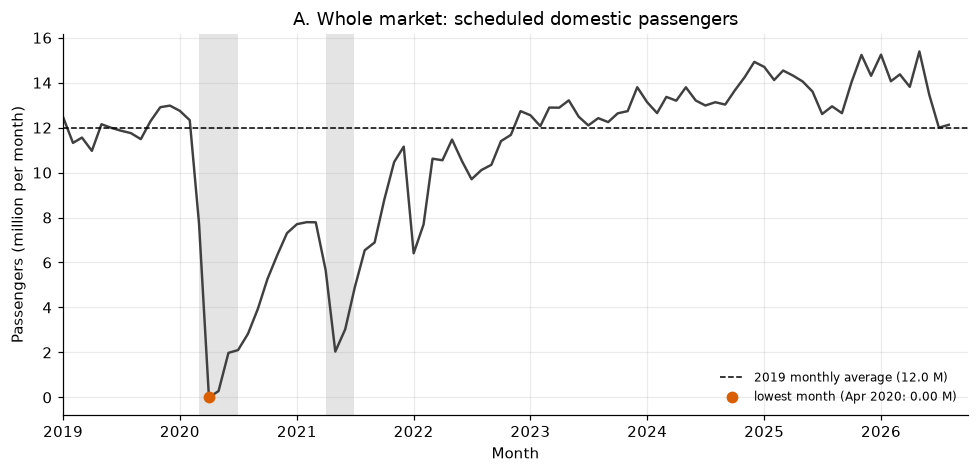

**A.** The market carried 12.0 million passengers a month in 2019 and fell to 0.00 million in April 2020, 100% below that average. The latest 12 months average 13.9 million, 116% of 2019, so the market as a whole is back.

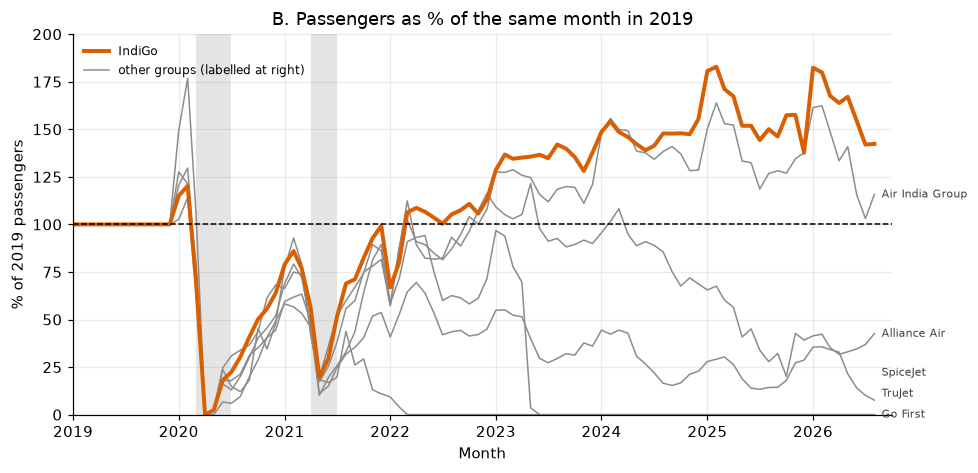

**B.** IndiGo first reached its 2019 level in May 2022 and is now at 146% of 2019. Air India Group first got there in December 2022 and is at 111%, while SpiceJet never did and sits at 11%.

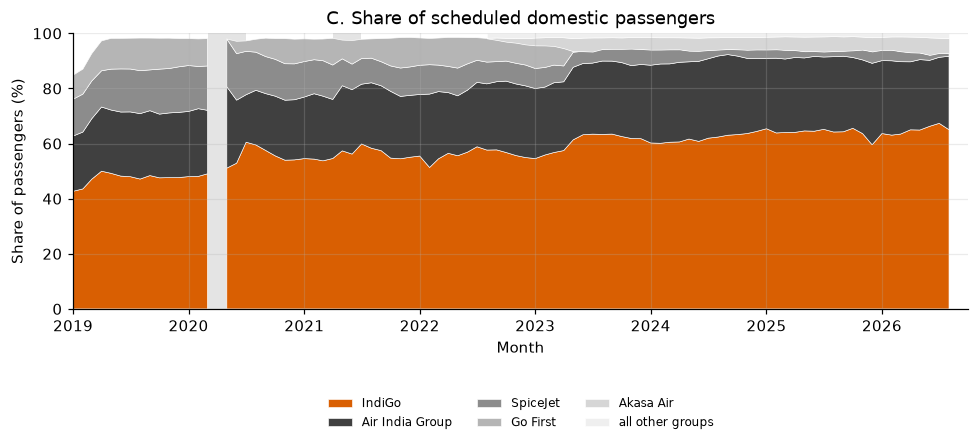

**C.** IndiGo's share of passengers rose from 47% across 2019 to 66% in the latest three months. Air India Group moved from 23% to 25%, and SpiceJet from 15% to 2%.

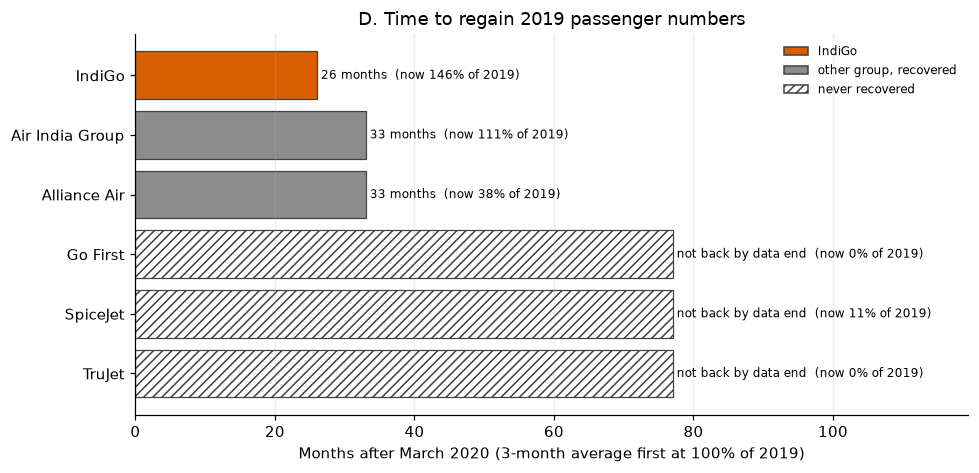

**D.** IndiGo needed 26 months from March 2020 to get its 3-month average back to 2019 and Air India Group 33. 3 of the 6 groups never did; Alliance Air crossed 100% once but is now at 38% of 2019.

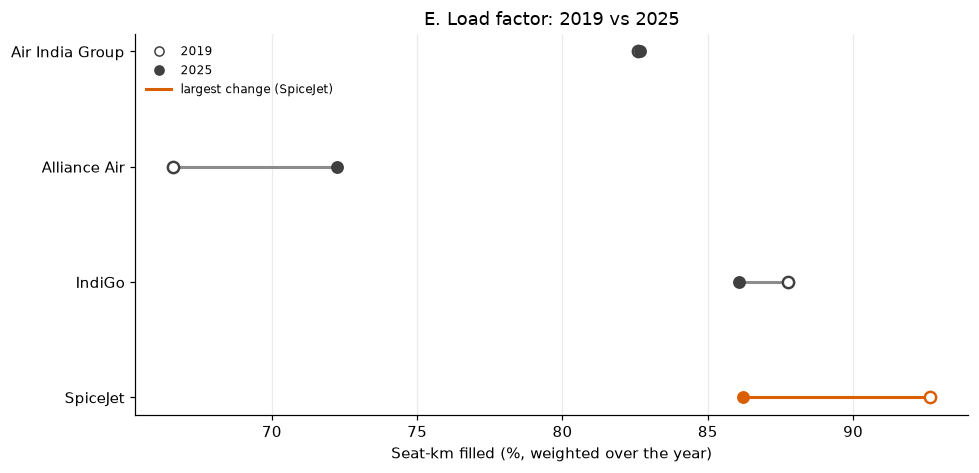

**E.** SpiceJet shows the largest change: its weighted load factor went from 92.7% in 2019 to 86.2% in 2025. IndiGo moved from 87.8% to 86.1%, so its growth did not come from emptier planes. Go First and TruJet are missing because they had stopped flying before 2025.

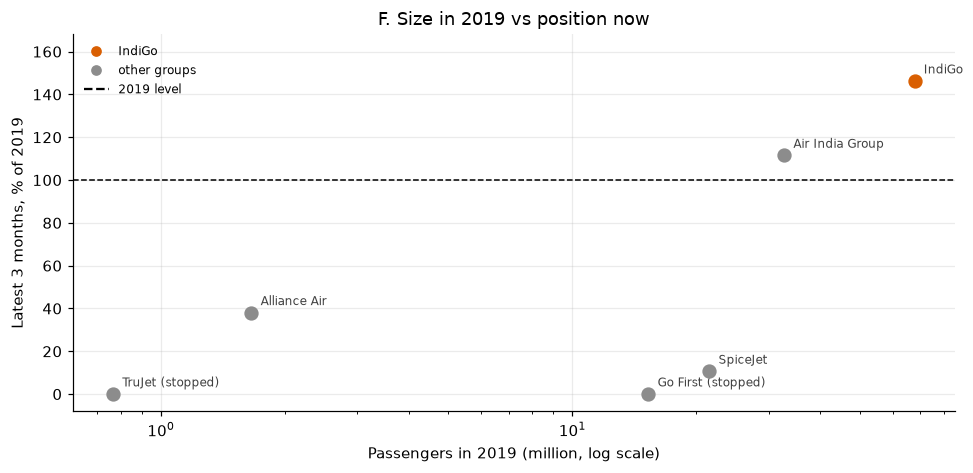

**F.** The two groups that carried most passengers in 2019, IndiGo (68 million) and Air India Group (33 million), are the only large ones above 100% today. Go First (15 million in 2019) and SpiceJet (22 million) were the next biggest and are at 0% and 11%.

In [6]:
# DASHBOARD: six panels, each a function so it can be shown alone (with its caption) and in the combined figure
def shade(ax):
    for a, b in COVID:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=LIGHT, alpha=.55, lw=0)

def p_total(ax):
    t = total.loc[START:] / 1e6; avg19 = total[total.index.year == 2019].mean() / 1e6; tr = t.idxmin()
    shade(ax); ax.plot(t.index, t, color=DARK, lw=1.6)
    ax.axhline(avg19, color="black", ls="--", lw=1, label=f"2019 monthly average ({avg19:.1f} M)")
    ax.scatter([tr], [t.min()], color=HIGHLIGHT, s=45, zorder=5, label=f"lowest month ({tr:%b %Y}: {t.min():.2f} M)")
    ax.set(title="A. Whole market: scheduled domestic passengers", xlabel="Month", ylabel="Passengers (million per month)", xlim=XLIM)
    ax.legend(loc="lower right", frameon=False, fontsize=8)
    return avg19, t.min(), tr, total.iloc[-12:].mean() / 1e6

def p_recovery(ax):
    shade(ax)
    for g in keep:
        if g != HL: ax.plot(ratio.index, ratio[g] * 100, color=MID, lw=1)
    ax.plot(ratio.index, ratio[HL] * 100, color=HIGHLIGHT, lw=2.6, label=HL)
    ax.plot([], [], color=MID, lw=1, label="other groups (labelled at right)")
    ax.axhline(100, color="black", ls="--", lw=1)
    prev = -99
    for v, g in sorted((ratio[g].iloc[-1] * 100, g) for g in keep if g != HL):
        yy = max(v, prev + 11); prev = yy
        ax.annotate(g, (ratio.index[-1], v), xytext=(ratio.index[-1] + pd.Timedelta(days=25), yy), fontsize=7.5, color=DARK, va="center")
    ax.set(title="B. Passengers as % of the same month in 2019", xlabel="Month", ylabel="% of 2019 passengers", xlim=XLIM, ylim=(0, 200))
    ax.legend(loc="upper left", frameon=False, fontsize=8)

def p_share(ax):
    sh = paxf.div(total, axis=0).loc[START:] * 100
    order = [g for g in ["IndiGo", "Air India Group", "SpiceJet", "Go First", "Akasa Air"] if g in sh.columns]
    other = 100 - sh[order].sum(axis=1)
    shades = [HIGHLIGHT, DARK, MID, "#b5b5b5", "#d6d6d6"][:len(order)] + ["#efefef"]
    ys = [sh[g] for g in order] + [other]; labels = order + ["all other groups"]
    cum = np.zeros(len(sh)); shade(ax)
    for y, c, lab in zip(ys, shades, labels):
        ax.fill_between(sh.index, cum, cum + y.values, color=c, lw=.4, edgecolor="white", label=lab); cum += y.values
    ax.set(title="C. Share of scheduled domestic passengers", xlabel="Month", ylabel="Share of passengers (%)", xlim=XLIM, ylim=(0, 100))
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3, fontsize=8, frameon=False)
    return sh, order

n_end = (LAST_COMPLETE.year - 2020) * 12 + LAST_COMPLETE.month - 3
def p_months(ax):
    r = res.assign(rec=res.months.notna(), m=res.months.fillna(n_end)).sort_values(["rec", "m"], ascending=[False, True]).reset_index(drop=True)
    for i, row in r.iterrows():
        col = HIGHLIGHT if row.Group == HL else (MID if row.rec else "white")
        ax.barh(i, row.m, color=col, edgecolor=DARK, hatch=None if row.rec else "////", lw=.8)
        txt = f"{row.m:.0f} months" if row.rec else "not back by data end"
        ax.text(row.m + .6, i, f"{txt}  (now {row.latest:.0f}% of 2019)", va="center", fontsize=8)
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.Group); ax.invert_yaxis(); ax.grid(axis="y", alpha=0)
    ax.set(title="D. Time to regain 2019 passenger numbers", xlabel="Months after March 2020 (3-month average first at 100% of 2019)", xlim=(0, n_end * 1.55))
    ax.legend(handles=[Patch(facecolor=HIGHLIGHT, edgecolor=DARK, label=HL), Patch(facecolor=MID, edgecolor=DARK, label="other group, recovered"),
                       Patch(facecolor="white", edgecolor=DARK, hatch="////", label="never recovered")], loc="upper right", frameon=False, fontsize=8)
    return r

LF_YEAR = 2025          # last full calendar year in the data
lf = (sdc.assign(yr=sdc.Date.dt.year).groupby(["Group", "yr"])[["Passenger Kilometers", "Seat Kilometers"]].sum(min_count=1))
lf["lf"] = lf["Passenger Kilometers"] / lf["Seat Kilometers"].where(lf["Seat Kilometers"] > 0) * 100
lft = lf["lf"].unstack("yr")
lfg = [g for g in keep if pd.notna(lft.loc[g].get(2019)) and pd.notna(lft.loc[g].get(LF_YEAR))]
LF_HL = max(lfg, key=lambda g: abs(lft.loc[g, LF_YEAR] - lft.loc[g, 2019]))

def p_lf(ax):
    for i, g in enumerate(lfg):
        a, b = lft.loc[g, 2019], lft.loc[g, LF_YEAR]; c = HIGHLIGHT if g == LF_HL else DARK
        ax.plot([a, b], [i, i], color=c if g == LF_HL else MID, lw=2)
        ax.scatter([a], [i], facecolor="white", edgecolor=c, s=55, zorder=3, lw=1.6); ax.scatter([b], [i], color=c, s=55, zorder=3)
    ax.set_yticks(range(len(lfg))); ax.set_yticklabels(lfg); ax.invert_yaxis(); ax.grid(axis="y", alpha=0)
    ax.set(title=f"E. Load factor: 2019 vs {LF_YEAR}", xlabel="Seat-km filled (%, weighted over the year)")
    ax.legend(handles=[Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor=DARK, label="2019"),
                       Line2D([], [], marker="o", ls="", color=DARK, label=str(LF_YEAR)),
                       Line2D([], [], color=HIGHLIGHT, lw=2, label=f"largest change ({LF_HL})")], loc="upper left", frameon=False, fontsize=8)

def p_scatter(ax):
    ax.axhline(100, color="black", ls="--", lw=1)
    for _, r in res.iterrows():
        c = HIGHLIGHT if r.Group == HL else MID
        ax.scatter(r.pax_2019 / 1e6, r.latest, color=c, s=70, zorder=3)
        stopped = r.last_traffic < LAST_COMPLETE - pd.Timedelta(days=62)
        ax.annotate(r.Group + (" (stopped)" if stopped else ""), (r.pax_2019 / 1e6, r.latest), xytext=(6, 5), textcoords="offset points", fontsize=8, color=DARK)
    ax.set_xscale("log"); ax.set_ylim(-8, res.latest.max() * 1.15)
    ax.set(title="F. Size in 2019 vs position now", xlabel="Passengers in 2019 (million, log scale)", ylabel="Latest 3 months, % of 2019")
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=HIGHLIGHT, label=HL), Line2D([], [], marker="o", ls="", color=MID, label="other groups"),
                       Line2D([], [], color="black", ls="--", label="2019 level")], loc="upper left", frameon=False, fontsize=8)

# captions: numbers are computed, so they stay right if the data is re-collected
def L(g, k): return R.loc[g, k]
avg19, tmin, trd, l12 = p_total(plt.figure().add_subplot()); plt.close("all")
sh, order = p_share(plt.figure().add_subplot()); plt.close("all"); rdf = p_months(plt.figure().add_subplot()); plt.close("all")
first_n, last_n = sh.iloc[:12].mean(), sh.iloc[-3:].mean()
others = [g for g in keep if g not in (HL,)]
CAPS = {
 "A": f"The market carried {avg19:.1f} million passengers a month in 2019 and fell to {tmin:.2f} million in {trd:%B %Y}, {(1 - tmin / avg19) * 100:.0f}% below that average. "
      f"The latest 12 months average {l12:.1f} million, {l12 / avg19 * 100:.0f}% of 2019, so the market as a whole is back.",
 "B": f"{HL} first reached its 2019 level in {L(HL, 'recovered'):%B %Y} and is now at {L(HL, 'latest'):.0f}% of 2019. "
      f"Air India Group first got there in {L('Air India Group', 'recovered'):%B %Y} and is at {L('Air India Group', 'latest'):.0f}%, while SpiceJet never did and sits at {L('SpiceJet', 'latest'):.0f}%. "
      f"A first crossing can be temporary, so the table also holds the month from which a group stayed at or above 2019 for six months in a row.",
 "C": f"{HL}'s share of passengers rose from {first_n[HL]:.0f}% across 2019 to {last_n[HL]:.0f}% in the latest three months. "
      f"Air India Group moved from {first_n['Air India Group']:.0f}% to {last_n['Air India Group']:.0f}%, and SpiceJet from {first_n['SpiceJet']:.0f}% to {last_n['SpiceJet']:.0f}%.",
 "D": f"{HL} needed {L(HL, 'months'):.0f} months from March 2020 to get its 3-month average back to 2019 and Air India Group {L('Air India Group', 'months'):.0f}. "
      f"{int((~rdf.rec).sum())} of the {len(rdf)} groups never did; Alliance Air crossed 100% once but is now at {L('Alliance Air', 'latest'):.0f}% of 2019.",
 "E": f"{LF_HL} shows the largest change: its weighted load factor went from {lft.loc[LF_HL, 2019]:.1f}% in 2019 to {lft.loc[LF_HL, LF_YEAR]:.1f}% in {LF_YEAR}. "
      f"{HL} moved from {lft.loc[HL, 2019]:.1f}% to {lft.loc[HL, LF_YEAR]:.1f}%, so its growth did not come from emptier planes. Go First and TruJet are missing because they had stopped flying before {LF_YEAR}.",
 "F": f"The two groups that carried most passengers in 2019, {HL} ({L(HL, 'pax_2019') / 1e6:.0f} million) and Air India Group ({L('Air India Group', 'pax_2019') / 1e6:.0f} million), are the only large ones above 100% today. "
      f"Go First ({L('Go First', 'pax_2019') / 1e6:.0f} million in 2019) and SpiceJet ({L('SpiceJet', 'pax_2019') / 1e6:.0f} million) were the next biggest and are at {L('Go First', 'latest'):.0f}% and {L('SpiceJet', 'latest'):.0f}%.",
}
PANELS = [("A", p_total), ("B", p_recovery), ("C", p_share), ("D", p_months), ("E", p_lf), ("F", p_scatter)]
for key, fn in PANELS:
    fig, ax = plt.subplots(figsize=(9, 4.4)); fn(ax); fig.tight_layout()
    fig.savefig(FIG / f"dashboard_{key}_{TODAY}.png", dpi=200, bbox_inches="tight"); plt.show()
    display(Markdown(f"**{key}.** " + CAPS[key]))

## 7. Combined dashboard (for the slides)

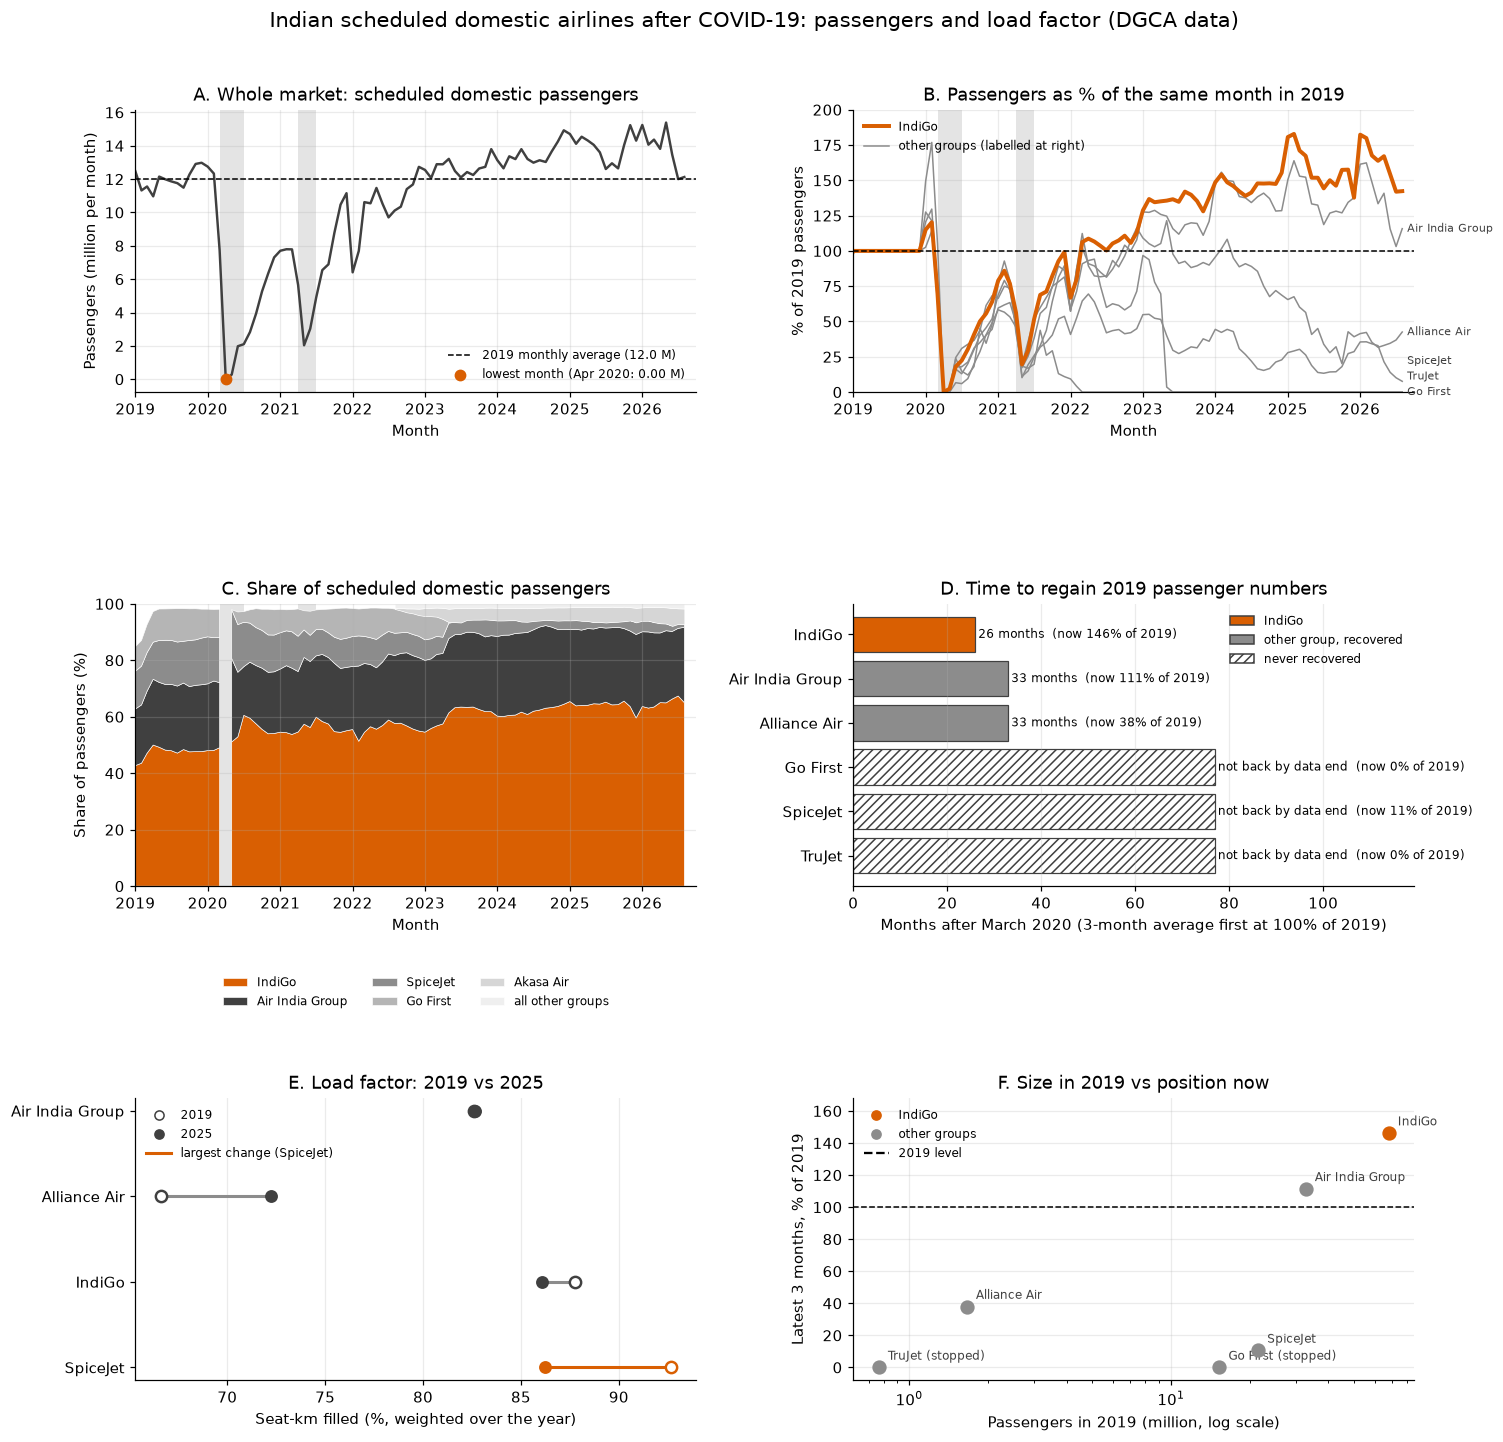

In [7]:
# COMBINED DASHBOARD (same six panels on one canvas; time axes are shared so the months line up)
fig = plt.figure(figsize=(15, 15)); gs = fig.add_gridspec(3, 2, hspace=0.75, wspace=0.28)
axA = fig.add_subplot(gs[0, 0]); axB = fig.add_subplot(gs[0, 1], sharex=axA); axC = fig.add_subplot(gs[1, 0], sharex=axA)
axD = fig.add_subplot(gs[1, 1]); axE = fig.add_subplot(gs[2, 0]); axF = fig.add_subplot(gs[2, 1])
for fn, ax in zip([p_total, p_recovery, p_share, p_months, p_lf, p_scatter], [axA, axB, axC, axD, axE, axF]):
    fn(ax)
fig.suptitle("Indian scheduled domestic airlines after COVID-19: passengers and load factor (DGCA data)", fontsize=14, y=0.94)
fig.savefig(FIG / f"dashboard_combined_{TODAY}.png", dpi=200, bbox_inches="tight"); plt.show()

## 8. Attributions and contributions (edit before submitting)

**Data sources**

| Source | URL | Collected | Licence and checks |
|---|---|---|---|
| DGCA monthly traffic and operating statistics (Excel) | https://www.dgca.gov.in/digigov-portal/?baseLocale=en_US?page=259/4184/servicename (files on https://public-prd-dgca.s3.ap-south-1.amazonaws.com) | 2026-11-01 | Government of India data. **Quote the portal's terms of use here.** robots.txt: HTTP 404 on www.dgca.gov.in and HTTP 403 on the S3 host, so none is published. |
| Vonter/india-aviation-traffic (parsed copy of the same DGCA files) | https://github.com/Vonter/india-aviation-traffic, commit e197170f131e43169620e4f8aa520350d4cbcba9 | 2026-11-01 | ODbL according to the repo README: re-check the LICENSE file and quote it. robots.txt on raw.githubusercontent.com: HTTP 404. |

The GitHub data is a second parse of the same DGCA files, not an independent measurement. Say so in the limitations: it validates our parser, not DGCA's reporting. The data is also labelled "Provisional" in the DGCA headers and comes from airlines' ICAO Form A returns.

**Libraries:** pandas, numpy, matplotlib, scipy, openpyxl, pyarrow, requests, selenium, IPython/Jupyter (add versions from `pip freeze`).

**AI tool:** Claude (Anthropic): *edit to match what you actually did*, for example "helped write and debug the download, parsing, cleaning and plotting notebooks and the data dictionary wording; the team ran every cell and checked the outputs".

**Contributions**

| Team member | What they did |
|---|---|
| | |
| | |
| | |